# 01 — EDA and Transaction Preparation

Chạy từ đầu đến cuối tại thư mục project hoặc `notebooks/`. Môi trường cần pandas, NumPy, Matplotlib, Seaborn, openpyxl và pyarrow; notebook không tự cài thư viện.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
assert (project_root / "config.py").is_file(), "Chạy tại project root hoặc notebooks/."
sys.path.insert(0, str(project_root))
from config import PROJECT_ROOT, RAW_DATA_FILE, PROCESSED_DATA_DIR, TABLES_DIR

sns.set_theme(style="whitegrid")

Matplotlib is building the font cache; this may take a moment.


## Data Understanding


In [2]:
raw = pd.read_excel(
    RAW_DATA_FILE, engine="openpyxl",
    dtype={"InvoiceNo": "string", "StockCode": "string"},
)
required_columns = {
    "InvoiceNo", "StockCode", "Description", "Quantity",
    "InvoiceDate", "UnitPrice", "CustomerID", "Country",
}
assert required_columns.issubset(raw.columns)

cancelled = raw["InvoiceNo"].str.upper().str.startswith("C", na=False)
raw_profile = pd.Series({
    "rows": len(raw),
    "columns": raw.shape[1],
    "invoices": raw["InvoiceNo"].nunique(),
    "stock_codes": raw["StockCode"].nunique(),
    "exact_duplicate_rows": int(raw.duplicated().sum()),
    "cancelled_rows": int(cancelled.sum()),
    "cancelled_invoices": raw.loc[cancelled, "InvoiceNo"].nunique(),
    "cancelled_invoice_pct": 100 * raw.loc[cancelled, "InvoiceNo"].nunique() / raw["InvoiceNo"].nunique(),
    "first_date": raw["InvoiceDate"].min(),
    "last_date": raw["InvoiceDate"].max(),
}, name="Raw data")
schema = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing_count": raw.isna().sum(),
    "missing_pct": raw.isna().mean().mul(100).round(2),
})
display(raw.head(), raw_profile, schema)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


rows                                  541909
columns                                    8
invoices                               25900
stock_codes                             4070
exact_duplicate_rows                    5268
cancelled_rows                          9288
cancelled_invoices                      3836
cancelled_invoice_pct              14.810811
first_date               2010-12-01 08:26:00
last_date                2011-12-09 12:50:00
Name: Raw data, dtype: object

,dtype,missing_count,missing_pct
InvoiceNo,string,0,0.00
StockCode,string,0,0.00
Description,object,1454,0.27
Quantity,int64,0,0.00
InvoiceDate,datetime64[us],0,0.00
UnitPrice,float64,0,0.00
CustomerID,float64,135080,24.93
Country,str,0,0.00


In [3]:
# Chỉ tìm ứng viên để kiểm tra; định dạng mã không phải quy tắc loại bỏ.
unusual_code = ~raw["StockCode"].str.fullmatch(r"\d{5}[A-Za-z]*", na=False)
service_description = raw["Description"].fillna("").str.contains(
    r"postage|packing charge|gift voucher|bank charges|adjust bad debt|"
    r"commission|amazon fee|^manual$|^discount$|^samples$|^carriage$",
    case=False, regex=True, na=False,
)
code_review = (
    raw.loc[unusual_code | service_description]
    .groupby("StockCode", dropna=False)
    .agg(
        rows=("StockCode", "size"),
        description_examples=("Description", lambda s: " | ".join(s.dropna().astype(str).unique()[:3])),
    )
)
display(code_review)

,rows,description_examples
StockCode,,
21656,1,samples
22016,1,Dotcomgiftshop Gift Voucher £100.00
23574,16,PACKING CHARGE
AMAZONFEE,34,AMAZON FEE
B,3,Adjust bad debt
BANK CHARGES,37,Bank Charges
C2,144,CARRIAGE
CRUK,16,CRUK Commission
D,77,Discount


## Cleaning
- Bỏ khoảng trắng đầu/cuối `InvoiceNo` và `StockCode`, chuyển `StockCode` thành chữ hoa. Loại dòng thiếu các mã này; không suy đoán mã bị thiếu.
- Chuyển `Description` sang kiểu chuỗi và bỏ khoảng trắng đầu/cuối; giữ nguyên giá trị thiếu.
- Loại hóa đơn có prefix `C` vì đó là hủy/hoàn trả. Tiếp tục loại `Quantity` hoặc `UnitPrice` thiếu, không hữu hạn hoặc ≤ 0. Đây là tập giao dịch mua dương, không phải doanh thu ròng; không tự ghép hủy với hóa đơn mua gốc.
- Bảng kiểm tra cho thấy `POST`, `DOT`, `C2` là vận chuyển; `D`, `M/m`, `BANK CHARGES`, `AMAZONFEE`, `CRUK`, `B` là giảm giá/phí/điều chỉnh; `S` là mẫu thử. Loại các mã này, các voucher đã xác minh (kể cả mã số `22016`) và phí đóng gói `23574`. Giữ mã hàng thật như `DCGS...` và `PADS` khi giao dịch hợp lệ, dù định dạng mã khác thông thường.
- Giữ dòng thiếu `CustomerID` vì phân tích dựa trên hóa đơn, không dựa trên khách hàng. Không tự điền mô tả hoặc loại hàng chỉ vì thiếu mô tả.
- Giữ duplicate hoàn toàn: không có mã dòng giao dịch để xác nhận đó là lỗi hay dòng mua lặp hợp lệ. Chỉ khử trùng cặp `InvoiceNo, StockCode` khi tạo `invoice_items`, đảm bảo mỗi sản phẩm được đếm tối đa một lần trong một hóa đơn.

Các bước loại bỏ được ghi tuần tự, nên mỗi dòng bị loại chỉ được tính một lần trong bảng audit.

In [4]:
transactions = raw.copy()
for column in ["InvoiceNo", "StockCode"]:
    transactions[column] = transactions[column].str.strip().replace("", pd.NA)
transactions["StockCode"] = transactions["StockCode"].str.upper()
transactions["Description"] = transactions["Description"].astype("string").str.strip()

non_product_codes = {
    "POST", "DOT", "C2", "D", "M", "BANK CHARGES", "AMAZONFEE",
    "CRUK", "B", "S", "23574", "22016",
    "GIFT_0001_10", "GIFT_0001_20", "GIFT_0001_30", "GIFT_0001_40", "GIFT_0001_50",
}
removal_rules = {
    "missing_invoice": transactions["InvoiceNo"].isna(),
    "missing_stock_code": transactions["StockCode"].isna(),
    "cancelled_invoice": transactions["InvoiceNo"].str.upper().str.startswith("C", na=False),
    "invalid_quantity": ~np.isfinite(transactions["Quantity"]) | transactions["Quantity"].le(0),
    "invalid_unit_price": ~np.isfinite(transactions["UnitPrice"]) | transactions["UnitPrice"].le(0),
    "non_product_line": transactions["StockCode"].str.upper().isin(non_product_codes),
}
keep = pd.Series(True, index=transactions.index)
cleaning_log = []
for rule, invalid in removal_rules.items():
    before = int(keep.sum())
    keep &= ~invalid
    cleaning_log.append({"metric": rule, "before": before, "after": int(keep.sum())})

cleaned_transactions = transactions.loc[keep].reset_index(drop=True)
cleaning_audit = pd.DataFrame(cleaning_log)
cleaning_audit["removed_rows"] = cleaning_audit["before"] - cleaning_audit["after"]
display(cleaning_audit)

,metric,before,after,removed_rows
0,missing_invoice,541909,541909,0
1,missing_stock_code,541909,541909,0
2,cancelled_invoice,541909,532621,9288
3,invalid_quantity,532621,531285,1336
4,invalid_unit_price,531285,530104,1181
5,non_product_line,530104,527746,2358


In [5]:
invoice_items = (
    cleaned_transactions[["InvoiceNo", "StockCode"]]
    .drop_duplicates()
    .sort_values(["InvoiceNo", "StockCode"])
    .reset_index(drop=True)
)
display(invoice_items.head())

,InvoiceNo,StockCode
0,536365,21730
1,536365,22752
2,536365,71053
3,536365,84029E
4,536365,84029G


## EDA Findings
Tần suất mua của một sản phẩm là số hóa đơn phân biệt chứa sản phẩm đó, không phải số dòng hoặc tổng số lượng. Kích thước giỏ là số `StockCode` phân biệt trong hóa đơn. Bảng 10 sản phẩm xuất hiện nhiều nhất chỉ dùng mô tả; không lọc dữ liệu đầu ra.

In [6]:
basket_sizes = invoice_items.groupby("InvoiceNo").size()
product_frequency = invoice_items["StockCode"].value_counts().rename("invoice_count")
monthly_invoices = cleaned_transactions.groupby(
    cleaned_transactions["InvoiceDate"].dt.to_period("M")
)["InvoiceNo"].nunique()

display(
    basket_sizes.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).to_frame("distinct_products_per_invoice"),
    product_frequency.describe().to_frame("invoices_per_product"),
    product_frequency.head(10).to_frame(),
)
display(Markdown(
    f"Sau cleaning còn **{len(cleaned_transactions):,} dòng**, "
    f"**{invoice_items['InvoiceNo'].nunique():,} hóa đơn** và "
    f"**{invoice_items['StockCode'].nunique():,} sản phẩm**. "
    f"Trung vị giỏ hàng là **{basket_sizes.median():.0f} sản phẩm**, "
    f"lớn nhất **{basket_sizes.max():,} sản phẩm**. "
    f"Có **{basket_sizes.eq(1).sum():,} hóa đơn một sản phẩm**; vẫn giữ chúng "
    "trong tập hóa đơn hợp lệ cho các bước nghiên cứu tiếp theo."
))

,distinct_products_per_invoice
count,19773.000000
mean,26.160674
std,47.019193
min,1.000000
25%,6.000000
50%,15.000000
75%,29.000000
90%,52.000000
99%,218.000000
max,1106.000000


,invoices_per_product
count,3797.0
mean,136.232552
std,195.592011
min,1.0
25%,18.0
50%,69.0
75%,171.0
max,2265.0


,invoice_count
StockCode,
85123A,2265
85099B,2089
22423,1988
47566,1685
20725,1565
84879,1455
22197,1392
22720,1385
21212,1320


Sau cleaning còn **527,746 dòng**, **19,773 hóa đơn** và **3,797 sản phẩm**. Trung vị giỏ hàng là **15 sản phẩm**, lớn nhất **1,106 sản phẩm**. Có **1,501 hóa đơn một sản phẩm**; vẫn giữ chúng trong tập hóa đơn hợp lệ cho các bước nghiên cứu tiếp theo.

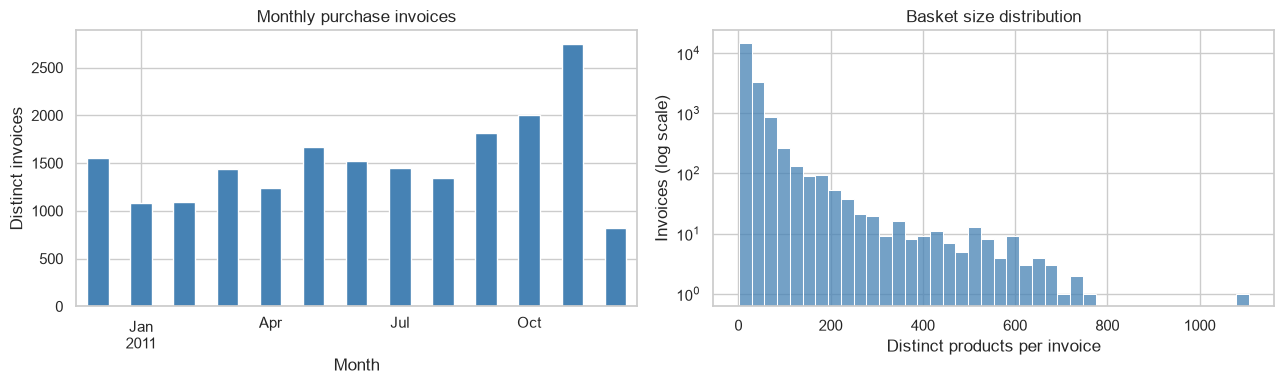

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
monthly_invoices.plot.bar(ax=axes[0], color="steelblue")
axes[0].set(title="Monthly purchase invoices", xlabel="Month", ylabel="Distinct invoices")
sns.histplot(basket_sizes, bins=40, ax=axes[1], color="steelblue")
axes[1].set_yscale("log")
axes[1].set(title="Basket size distribution", xlabel="Distinct products per invoice", ylabel="Invoices (log scale)")
plt.tight_layout()
plt.show()

Dữ liệu kết thúc ngày 09/12/2011, vì vậy tháng 12/2011 chưa đủ tháng; không diễn giải số hóa đơn thấp hơn là giảm nhu cầu. Biểu đồ kích thước giỏ dùng trục tung log để quan sát cả giỏ hiếm. Giữ các giỏ lớn và giao dịch dương bất thường vì chưa có bằng chứng chúng sai; chúng có thể phản ánh mua sỉ. Dòng trùng được giữ nên thống kê số dòng/số lượng cần thận trọng; thống kê hiện diện sản phẩm dùng cặp hóa đơn–sản phẩm duy nhất.

## Validation
Đối chiếu before/after trên các chỉ số chất lượng và kiểm tra bảo toàn số dòng qua audit. Xác nhận giao dịch sạch hợp lệ, không mất sản phẩm/hóa đơn khi chuyển sang bảng hiện diện và không còn cặp trùng. `data_quality.csv` gồm hai phần: `summary` (trước/sau toàn bộ cleaning) và `cleaning` (số dòng trước/sau từng quy tắc).

In [8]:
summaries = {}
for stage, frame in [("before", raw), ("after", cleaned_transactions)]:
    summaries[stage] = {
        "rows": len(frame),
        "invoices": frame["InvoiceNo"].nunique(),
        "products": frame["StockCode"].nunique(),
        "exact_duplicate_rows": int(frame.duplicated().sum()),
        "repeated_invoice_product_rows": int(frame.duplicated(["InvoiceNo", "StockCode"]).sum()),
        "missing_invoice": int(frame["InvoiceNo"].isna().sum()),
        "missing_stock_code": int(frame["StockCode"].isna().sum()),
        "missing_description": int(frame["Description"].isna().sum()),
        "missing_customer_id": int(frame["CustomerID"].isna().sum()),
        "cancelled_rows": int(frame["InvoiceNo"].str.upper().str.startswith("C", na=False).sum()),
        "invalid_quantity_rows": int((~np.isfinite(frame["Quantity"]) | frame["Quantity"].le(0)).sum()),
        "invalid_unit_price_rows": int((~np.isfinite(frame["UnitPrice"]) | frame["UnitPrice"].le(0)).sum()),
        "non_product_rows": int(frame["StockCode"].str.upper().isin(non_product_codes).sum()),
    }
quality_summary = pd.DataFrame(summaries).rename_axis("metric").reset_index()
data_quality = pd.concat([
    quality_summary.assign(section="summary"),
    cleaning_audit.assign(section="cleaning"),
], ignore_index=True)[["section", "metric", "before", "after"]]

assert not cleaned_transactions.empty
assert len(cleaned_transactions) + cleaning_audit["removed_rows"].sum() == len(raw)
assert (cleaned_transactions["Quantity"] > 0).all() and np.isfinite(cleaned_transactions["Quantity"]).all()
assert (cleaned_transactions["UnitPrice"] > 0).all() and np.isfinite(cleaned_transactions["UnitPrice"]).all()
assert cleaned_transactions[["InvoiceNo", "StockCode"]].notna().all().all()
assert not cleaned_transactions["InvoiceNo"].str.upper().str.startswith("C").any()
assert not cleaned_transactions["StockCode"].str.upper().isin(non_product_codes).any()
assert cleaned_transactions["StockCode"].equals(cleaned_transactions["StockCode"].str.upper())
assert cleaned_transactions["Description"].equals(cleaned_transactions["Description"].str.strip())
assert not invoice_items.duplicated(["InvoiceNo", "StockCode"]).any()
assert len(invoice_items) == cleaned_transactions.groupby(["InvoiceNo", "StockCode"]).ngroups
assert set(invoice_items["InvoiceNo"]) == set(cleaned_transactions["InvoiceNo"])
assert set(invoice_items["StockCode"]) == set(cleaned_transactions["StockCode"])
display(data_quality)

,section,metric,before,after
0,summary,rows,541909,527746
1,summary,invoices,25900,19773
2,summary,products,4070,3797
3,summary,exact_duplicate_rows,5268,5221
4,summary,repeated_invoice_product_rows,10684,10471
5,summary,missing_invoice,0,0
6,summary,missing_stock_code,0,0
7,summary,missing_description,1454,0
8,summary,missing_customer_id,135080,131420
9,summary,cancelled_rows,9288,0


## Saved Outputs
Lưu toàn bộ giao dịch mua hợp lệ vào `cleaned_transactions.parquet` và bảng hai cột `InvoiceNo`, `StockCode` vào `invoice_items.parquet`. Bảng `data_quality.csv` lưu before/after và audit cleaning. Đọc lại ba file để kiểm tra dữ liệu lưu khớp nội dung. Cell cuối xuất thêm hai file CSV cùng tên trong `data/processed/`.

In [9]:
cleaned_path = PROCESSED_DATA_DIR / "cleaned_transactions.parquet"
items_path = PROCESSED_DATA_DIR / "invoice_items.parquet"
quality_path = TABLES_DIR / "data_quality.csv"

cleaned_transactions.to_parquet(cleaned_path, engine="pyarrow", index=False)
invoice_items.to_parquet(items_path, engine="pyarrow", index=False)
data_quality.to_csv(quality_path, index=False)

# Cho phép khác kiểu object/string khi đọc lại; vẫn kiểm tra giá trị và cấu trúc.
pd.testing.assert_frame_equal(pd.read_parquet(cleaned_path), cleaned_transactions, check_dtype=False)
pd.testing.assert_frame_equal(pd.read_parquet(items_path), invoice_items, check_dtype=False)
pd.testing.assert_frame_equal(pd.read_csv(quality_path), data_quality, check_dtype=False)
display(pd.DataFrame({
    "output": [str(path.relative_to(PROJECT_ROOT)) for path in [cleaned_path, items_path, quality_path]],
    "rows": [len(cleaned_transactions), len(invoice_items), len(data_quality)],
}))

,output,rows
0,data/processed/cleaned_transactions.parquet,527746
1,data/processed/invoice_items.parquet,517275
2,outputs/tables/data_quality.csv,19


In [10]:
for filename in ["cleaned_transactions", "invoice_items"]:
    pd.read_parquet(PROCESSED_DATA_DIR / f"{filename}.parquet").to_csv(
        PROCESSED_DATA_DIR / f"{filename}.csv", index=False, encoding="utf-8-sig"
    )